In [8]:
import pandas as pd
import numpy as np
import ast
import wfdb
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# ── 1. Load and label ──────────────────────────────────────────────
PATH = './ptbxl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3/'

df = pd.read_csv(PATH + 'ptbxl_database.csv')
scp_df = pd.read_csv(PATH + 'scp_statements.csv', index_col=0)
df['scp_codes'] = df['scp_codes'].apply(ast.literal_eval)

def get_superclass(scp_dict):
    superclasses = []
    for code in scp_dict.keys():
        if code in scp_df.index:
            sc = scp_df.loc[code, 'diagnostic_class']
            if pd.notna(sc):
                superclasses.append(sc)
    return list(set(superclasses)) if superclasses else ['UNKNOWN']

df['superclass'] = df['scp_codes'].apply(get_superclass)

def map_label(superclasses):
    if 'MI' in superclasses:
        return 2  # Critical
    elif 'NORM' in superclasses:
        return 0  # Normal
    elif 'UNKNOWN' in superclasses:
        return -1  # drop
    else:
        return 1  # Abnormal

df['label'] = df['superclass'].apply(map_label)
df = df[df['label'] != -1].reset_index(drop=True)
print("Label distribution:\n", df['label'].value_counts())

# ── 2. Load ECG signals ────────────────────────────────────────────
def load_ecg(filename):
    record = wfdb.rdsamp(PATH + filename)
    return record[0]  # shape: (1000, 12)

print("Loading ECG signals... this takes a few minutes")
X = np.array([load_ecg(f) for f in df['filename_lr']])
y = df['label'].values
print("X shape:", X.shape)

# ── 3. Split ───────────────────────────────────────────────────────
# X موجود بالفعل في الميموري، خذ Lead II فقط
X_single = X[:, :, 1:2]  # shape: (21388, 1000, 1)
print("New X shape:", X_single.shape)

# أعد التقسيم
X_train, X_test, y_train, y_test = train_test_split(
    X_single, y, test_size=0.2, random_state=42, stratify=y
)

# عدّل الـ model input shape
def build_cnn(input_shape=(1000, 1)):  # 1 بدل 12
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv1D(64, kernel_size=7, activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling1D(2),
        layers.Conv1D(128, kernel_size=5, activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling1D(2),
        layers.Conv1D(256, kernel_size=5, activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling1D(2),
        layers.Conv1D(256, kernel_size=3, activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.GlobalAveragePooling1D(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(3, activation='softmax')
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

model = build_cnn()
model.summary()

Label distribution:
 label
0    9513
1    6406
2    5469
Name: count, dtype: int64
Loading ECG signals... this takes a few minutes
X shape: (21388, 1000, 12)
New X shape: (21388, 1000, 1)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_8 (Conv1D)               │ (None, 1000, 64)       │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 1000, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_6 (MaxPooling1D)  │ (None, 500, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_9 (Conv1D)               │ (None, 500, 128)       │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 500, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_7 (MaxPooling1D)  │ (None, 250, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_10 (Conv1D)              │ (None, 250, 256)       │       164,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 250, 256)       │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_8 (MaxPooling1D)  │ (None, 125, 256)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_11 (Conv1D)              │ (None, 125, 256)       │       196,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 125, 256)       │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_2      │ (None, 256)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 446,723 (1.70 MB)

 Trainable params: 445,315 (1.70 MB)

 Non-trainable params: 1,408 (5.50 KB)

In [3]:
# Threshold 0.30
y_pred_30 = []
for probs in y_proba:
    if probs[2] > 0.30:
        y_pred_30.append(2)
    else:
        y_pred_30.append(np.argmax(probs[:2]))
y_pred_30 = np.array(y_pred_30)
print("--- Threshold 0.30 ---")
print(classification_report(y_test, y_pred_30,
      target_names=['Normal', 'Abnormal', 'Critical(MI)'], digits=3))

--- Threshold 0.30 ---
              precision    recall  f1-score   support

      Normal      0.838     0.892     0.864      1903
    Abnormal      0.761     0.634     0.692      1281
Critical(MI)      0.729     0.790     0.758      1094

    accuracy                          0.789      4278
   macro avg      0.776     0.772     0.771      4278
weighted avg      0.787     0.789     0.785      4278



In [4]:
# Threshold 0.25
y_pred_25 = []
for probs in y_proba:
    if probs[2] > 0.25:
        y_pred_25.append(2)
    else:
        y_pred_25.append(np.argmax(probs[:2]))
y_pred_25 = np.array(y_pred_25)
print("--- Threshold 0.25 ---")
print(classification_report(y_test, y_pred_25,
      target_names=['Normal', 'Abnormal', 'Critical(MI)'], digits=3))

--- Threshold 0.25 ---


              precision    recall  f1-score   support

      Normal      0.842     0.883     0.862      1903
    Abnormal      0.778     0.598     0.676      1281
Critical(MI)      0.696     0.826     0.756      1094

    accuracy                          0.783      4278
   macro avg      0.772     0.769     0.765      4278
weighted avg      0.786     0.783     0.779      4278



In [5]:
model.save('best_model_current.keras')

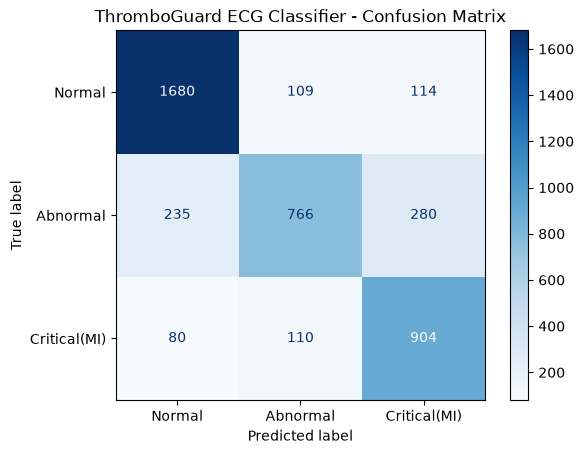

In [6]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_25)
disp = ConfusionMatrixDisplay(cm, display_labels=['Normal','Abnormal','Critical(MI)'])
disp.plot(cmap='Blues')
plt.title('ThromboGuard ECG Classifier - Confusion Matrix')
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()


In [10]:
import tensorflow as tf

m1 = tf.keras.models.load_model('best_model_current.keras')
print("best_model_current input shape:", m1.input_shape)

m2 = tf.keras.models.load_model('best_model.keras')
print("best_model input shape:", m2.input_shape)




best_model_current input shape: (None, 1000, 12)
best_model input shape: (None, 1000, 12)


In [11]:
# if the best model is 12-lead, rebuild X_test from original 12-lead X
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("X_test shape:", X_test.shape)  # should be (N, 1000, 12)

# then predict
y_proba = m1.predict(X_test)

y_pred_25 = []
for probs in y_proba:
    if probs[2] > 0.25:
        y_pred_25.append(2)
    else:
        y_pred_25.append(np.argmax(probs[:2]))

y_pred_25 = np.array(y_pred_25)
print(classification_report(y_test, y_pred_25,
      target_names=['Normal', 'Abnormal', 'Critical(MI)'], digits=3))

X_test shape: (4278, 1000, 12)
134/134 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step
              precision    recall  f1-score   support

      Normal      0.842     0.883     0.862      1903
    Abnormal      0.778     0.598     0.676      1281
Critical(MI)      0.696     0.826     0.756      1094

    accuracy                          0.783      4278
   macro avg      0.772     0.769     0.765      4278
weighted avg      0.786     0.783     0.779      4278



In [12]:
# X is already loaded (1000, 12), take Lead II only
X_single = X[:, :, 1:2]  # shape: (21388, 1000, 1)
print("Single lead shape:", X_single.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X_single, y, test_size=0.2, random_state=42, stratify=y
)

classes = np.unique(y_train)
weights = compute_class_weight('balanced', classes=classes, y=y_train)
class_weight_dict = dict(zip(classes, weights))

def build_resnet(input_shape=(1000, 1)):
    inputs = tf.keras.Input(shape=input_shape)
    
    # initial conv
    x = layers.Conv1D(64, kernel_size=7, padding='same')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling1D(2)(x)
    
    # residual block 1
    shortcut = layers.Conv1D(128, kernel_size=1, padding='same')(x)
    shortcut = layers.BatchNormalization()(shortcut)
    x = layers.Conv1D(128, kernel_size=5, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv1D(128, kernel_size=5, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Add()([x, shortcut])
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling1D(2)(x)
    
    # residual block 2
    shortcut = layers.Conv1D(256, kernel_size=1, padding='same')(x)
    shortcut = layers.BatchNormalization()(shortcut)
    x = layers.Conv1D(256, kernel_size=5, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv1D(256, kernel_size=5, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Add()([x, shortcut])
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling1D(2)(x)
    
    # residual block 3
    shortcut = layers.Conv1D(256, kernel_size=1, padding='same')(x)
    shortcut = layers.BatchNormalization()(shortcut)
    x = layers.Conv1D(256, kernel_size=3, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv1D(256, kernel_size=3, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Add()([x, shortcut])
    x = layers.Activation('relu')(x)
    
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(3, activation='softmax')(x)
    
    model = tf.keras.Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

model = build_resnet()
model.summary()

callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ModelCheckpoint('best_resnet_single_lead.keras', 
                    monitor='val_loss', save_best_only=True)
]

history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    class_weight=class_weight_dict,
    callbacks=callbacks
)

y_proba = model.predict(X_test)

for threshold in [0.25, 0.30, 0.35]:
    y_pred = []
    for probs in y_proba:
        if probs[2] > threshold:
            y_pred.append(2)
        else:
            y_pred.append(np.argmax(probs[:2]))
    y_pred = np.array(y_pred)
    print(f"\n--- Threshold {threshold} ---")
    print(classification_report(y_test, y_pred,
          target_names=['Normal', 'Abnormal', 'Critical(MI)'], digits=3))
    

Single lead shape: (21388, 1000, 1)


Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 1000, 1)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_12 (Conv1D)  │ (None, 1000, 64)  │        512 │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1000, 64)  │        256 │ conv1d_12[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 1000, 64)  │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_9     │ (None, 500, 64)   │          0 │ activation[0][0]  │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_14 (Conv1D)  │ (None, 500, 128)  │     41,088 │ max_pooling1d_9[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 500, 128)  │        512 │ conv1d_14[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 500, 128)  │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_15 (Conv1D)  │ (None, 500, 128)  │     82,048 │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_13 (Conv1D)  │ (None, 500, 128)  │      8,320 │ max_pooling1d_9[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 500, 128)  │        512 │ conv1d_15[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 500, 128)  │        512 │ conv1d_13[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 500, 128)  │          0 │ batch_normalizat… │
│                     │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 500, 128)  │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_10    │ (None, 250, 128)  │          0 │ activation_2[0][… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_17 (Conv1D)  │ (None, 250, 256)  │    164,096 │ max_pooling1d_10… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 250, 256)  │      1,024 │ conv1d_17[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 250, 256)  │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 1,165,827 (4.45 MB)

 Trainable params: 1,161,859 (4.43 MB)

 Non-trainable params: 3,968 (15.50 KB)

Epoch 1/50
482/482 ━━━━━━━━━━━━━━━━━━━━ 103s 205ms/step - accuracy: 0.6040 - loss: 0.8971 - val_accuracy: 0.3928 - val_loss: 1.1778
Epoch 2/50
482/482 ━━━━━━━━━━━━━━━━━━━━ 101s 209ms/step - accuracy: 0.6584 - loss: 0.8223 - val_accuracy: 0.6628 - val_loss: 0.7785
Epoch 3/50
482/482 ━━━━━━━━━━━━━━━━━━━━ 99s 205ms/step - accuracy: 0.6739 - loss: 0.8032 - val_accuracy: 0.6692 - val_loss: 0.7426
Epoch 4/50
482/482 ━━━━━━━━━━━━━━━━━━━━ 99s 205ms/step - accuracy: 0.6804 - loss: 0.7916 - val_accuracy: 0.6756 - val_loss: 0.7654
Epoch 5/50
482/482 ━━━━━━━━━━━━━━━━━━━━ 99s 206ms/step - accuracy: 0.6816 - loss: 0.7824 - val_accuracy: 0.6593 - val_loss: 0.7505
Epoch 6/50
482/482 ━━━━━━━━━━━━━━━━━━━━ 95s 197ms/step - accuracy: 0.6886 - loss: 0.7698 - val_accuracy: 0.6610 - val_loss: 0.7510
Epoch 7/50
482/482 ━━━━━━━━━━━━━━━━━━━━ 108s 223ms/step - accuracy: 0.6876 - loss: 0.7679 - val_accuracy: 0.6791 - val_loss: 0.7304
Epoch 8/50
482/482 ━━━━━━━━━━━━━━━━━━━━ 189s 392ms/step - accuracy: 0.6917 - los